### Setup: Download Dataset Automatically
Run this cell to download the dataset to your environment so you do not have to upload it manually every time.

In [1]:
# Replace the URL placeholder below with the actual link to your CSV file to automate downloads
# !wget -O /content/Final_data.csv "YOUR_DIRECT_DOWNLOAD_LINK_HERE"

# Regional & Disease-Specific Outbreak Analysis

A simple, interactive-by-editing Python notebook for exploring outbreak reports by **state, district, disease, and year**.

It includes four useful graphs:
1. Top 10 diseases by reported cases.
2. Year-wise case trend.
3. Top 10 districts by reported cases.
4. Month-wise reported cases.

**Data source:** `Final_data.csv` (the supplied dataset). These are reported counts, not population-adjusted incidence rates.

## 1. Import libraries

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Simple chart style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# Load the dataset from the workspace, with the original Colab location as a fallback.
data_path = Path("Final_data.csv")
if not data_path.is_file():
    data_path = Path("/content/Final_data.csv")
if not data_path.is_file():
    raise FileNotFoundError(
        f"Final_data.csv was not found in {Path.cwd()} or /content. "
        "Place the dataset beside the notebook or in /content."
    )

df = pd.read_csv(data_path)
print(f"Dataset loaded from {data_path}: {df.shape}")

Dataset loaded from Final_data.csv: (8985, 15)


In [3]:
# Check for missing values in each column
if 'df' in globals():
    print("--- Missing Values Count per Column ---")
    missing_counts = df.isnull().sum()
    missing_percentage = (df.isnull().sum() / len(df)) * 100
    missing_df = pd.DataFrame({'Missing Values': missing_counts, 'Percentage (%)': missing_percentage})
    display(missing_df)
else:
    print("DataFrame 'df' is not loaded. Please ensure 'Final_data.csv' is uploaded and loaded successfully first.")

--- Missing Values Count per Column ---


,Missing Values,Percentage (%)
Unnamed: 0,0,0.000000
week_of_outbreak,0,0.000000
state_ut,0,0.000000
district,0,0.000000
Disease,0,0.000000
Cases,0,0.000000
Deaths,6431,71.574847
day,0,0.000000
mon,0,0.000000
year,0,0.000000


## 2. Clean the data

In [4]:
# Remove the extra index column if it exists
df = df.drop(columns=["Unnamed: 0"], errors="ignore")

# Convert numeric columns to numbers
for col in ["Cases", "Deaths", "day", "mon", "year", "Latitude", "Longitude", "preci", "LAI", "Temp"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove spaces from category names
for col in ["state_ut", "district", "Disease"]:
    df[col] = df[col].astype("string").str.strip()

# Create a proper date column
df["Date"] = pd.to_datetime(
    dict(year=df["year"], month=df["mon"], day=df["day"]),
    errors="coerce"
)

# Keep valid, non-negative case counts
df = df[df["Cases"].notna() & (df["Cases"] >= 0)].copy()
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month

print("Records available:", len(df))
print("States/UTs:", df["state_ut"].nunique())
print("Districts:", df["district"].nunique())
print("Disease labels:", df["Disease"].nunique())

Records available: 8984
States/UTs: 36
Districts: 791
Disease labels: 22


## 3. Select the region and disease

**Change the values in this cell only** to explore another area or disease.

- `SELECT_STATE`: enter a state name exactly as shown in the dataset, or `"All"`.
- `SELECT_DISTRICT`: enter a district name exactly, or `"All"`.
- `SELECT_DISEASE`: enter a disease label exactly, or `"All"`.
- `SELECT_YEAR`: enter a year such as `2022`, or `"All"`.

Tip: Run this cell and check the printed lists if you are unsure of the exact spelling.

In [5]:
# ========== CHANGE YOUR ANALYSIS HERE ==========

SELECT_STATE = "Maharashtra"   # Change state here, e.g. "Kerala", "Meghalaya", or "All"
SELECT_DISTRICT = "All"        # Change district here, e.g. "Gadchiroli", or keep "All"
SELECT_DISEASE = "Malaria"     # Change disease here, e.g. "Dengue", or keep "All"
SELECT_YEAR = "All"            # Change year here, e.g. 2022, or keep "All"

# ===============================================

print("Available states:", sorted(df["state_ut"].dropna().unique()))
print("\\nAvailable diseases:", sorted(df["Disease"].dropna().unique()))

Available states: ['Andaman and Nicobar Islands', 'Andhra Pradesh', 'Arunachal Pradesh', 'Assam', 'Bihar', 'Chandigarh', 'Chhattisgarh', 'Dadra and Nagar Haveli', 'Daman and Diu', 'Delhi', 'Goa', 'Gujarat', 'Haryana', 'Himachal Pradesh', 'Jammu and Kashmir', 'Jharkhand', 'Karnataka', 'Kerala', 'Lakshadweep', 'Madhya Pradesh', 'Maharashtra', 'Manipur', 'Meghalaya', 'Mizoram', 'Nagaland', 'Odisha', 'Puducherry', 'Punjab', 'Rajasthan', 'Sikkim', 'Tamil Nadu', 'Telangana', 'Tripura', 'Uttar Pradesh', 'Uttarakhand', 'West Bengal']
\nAvailable diseases: ['Acute Diarrhoeal Disease', 'Acute Encephalitis Syndrome', 'Acute Gastroenteritis', 'Chikungunya', 'Chikungunya/ Dengue', 'Chikungunya/Dengue', 'Cholera', 'Dengue', 'Dengue And Chikungunya', 'Dengue And Malaria', 'Dengue Chikungunya', 'Dengue Fever', 'Dengue/Chikungunya', 'Diarrhea', 'Gastroenteritis', 'Malaria', 'Malaria (PV)', 'Suspected Chikungunya', 'Suspected Cholera', 'Suspected Dengue', 'Suspected Dengue And Chikungunya', 'pyrexia of 

## 4. Apply the selected filters

In [6]:
# Apply state, district, disease and year filters
filtered = df.copy()

if SELECT_STATE != "All":
    filtered = filtered[filtered["state_ut"].str.casefold() == SELECT_STATE.casefold()]

if SELECT_DISTRICT != "All":
    filtered = filtered[filtered["district"].str.casefold() == SELECT_DISTRICT.casefold()]

if SELECT_DISEASE != "All":
    filtered = filtered[filtered["Disease"].str.casefold() == SELECT_DISEASE.casefold()]

if SELECT_YEAR != "All":
    filtered = filtered[filtered["Year"] == int(SELECT_YEAR)]

if filtered.empty:
    print("No records found. Check the selected state, district, disease, and year.")
else:
    print("Matching records:", len(filtered))
    print("Reported cases:", f"{filtered['Cases'].sum():,.0f}")
    print("Recorded deaths:", f"{filtered['Deaths'].sum():,.0f}")
    print("Date range:", filtered["Date"].min(), "to", filtered["Date"].max())

Matching records:

 113
Reported cases: 3,742
Recorded deaths: 76
Date range: 2009-09-12 00:00:00 to 2022-06-13 00:00:00


## 5. Graph 1 — Top 10 diseases by reported cases

This graph uses the selected state and district (if selected), but shows all diseases in that area so that diseases can be compared. The year filter is also applied.

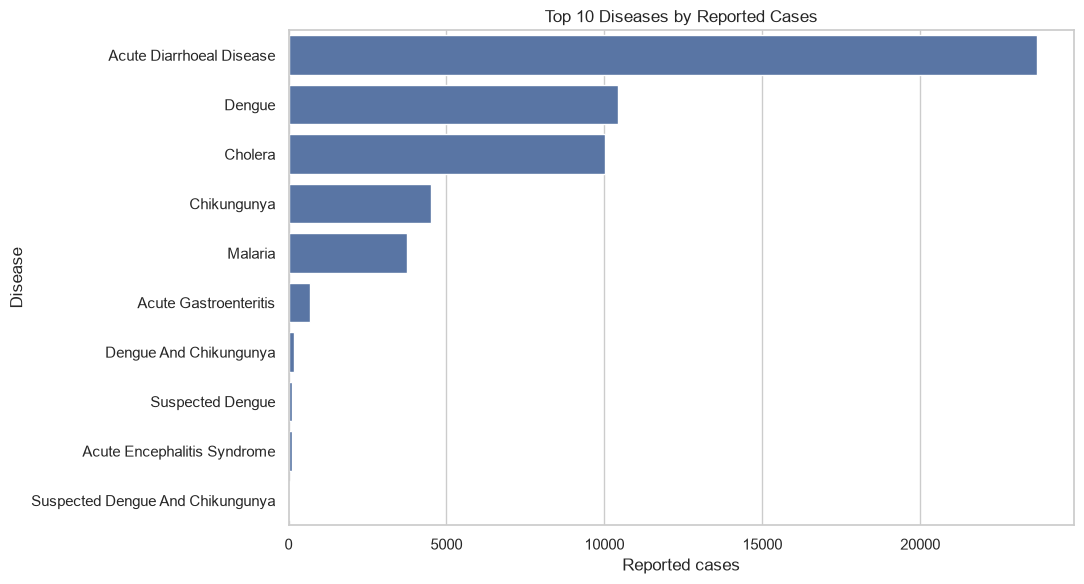

In [7]:
# Use the selected geography and year, but include every disease
disease_data = df.copy()

if SELECT_STATE != "All":
    disease_data = disease_data[disease_data["state_ut"].str.casefold() == SELECT_STATE.casefold()]
if SELECT_DISTRICT != "All":
    disease_data = disease_data[disease_data["district"].str.casefold() == SELECT_DISTRICT.casefold()]
if SELECT_YEAR != "All":
    disease_data = disease_data[disease_data["Year"] == int(SELECT_YEAR)]

top_diseases = (disease_data.groupby("Disease")["Cases"].sum()
                .sort_values(ascending=False).head(10).reset_index())

if not top_diseases.empty:
    plt.figure(figsize=(11, 6))
    sns.barplot(data=top_diseases, x="Cases", y="Disease", color="#4C72B0")
    plt.title("Top 10 Diseases by Reported Cases")
    plt.xlabel("Reported cases")
    plt.ylabel("Disease")
    plt.tight_layout()
    plt.show()
else:
    print("No data available for the selected geography/year.")

## 6. Graph 2 — Year-wise case trend for the selected disease

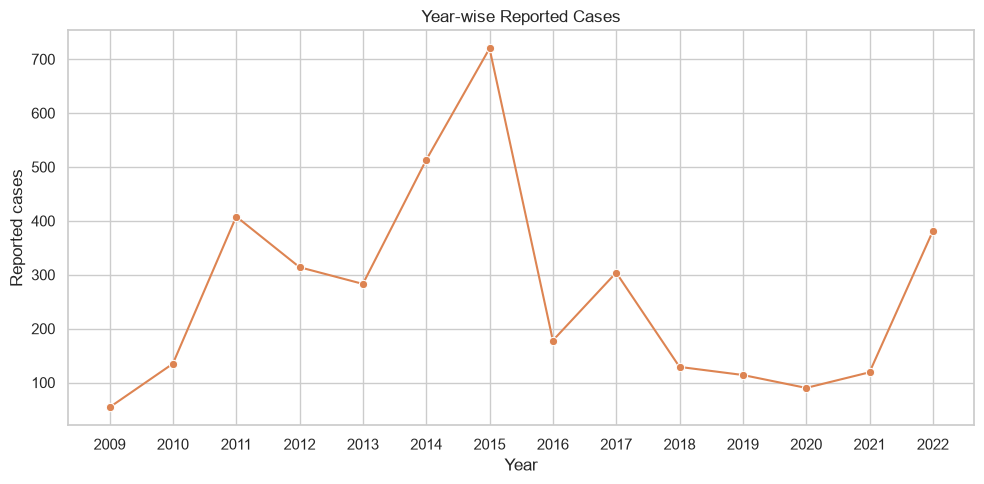

In [8]:
# This graph follows the selected disease and geography.
# If SELECT_DISEASE is "All", it shows the combined case trend for all diseases.

trend_data = df.copy()
if SELECT_STATE != "All":
    trend_data = trend_data[trend_data["state_ut"].str.casefold() == SELECT_STATE.casefold()]
if SELECT_DISTRICT != "All":
    trend_data = trend_data[trend_data["district"].str.casefold() == SELECT_DISTRICT.casefold()]
if SELECT_DISEASE != "All":
    trend_data = trend_data[trend_data["Disease"].str.casefold() == SELECT_DISEASE.casefold()]

year_trend = trend_data.groupby("Year", as_index=False)["Cases"].sum().dropna()

if not year_trend.empty:
    plt.figure(figsize=(10, 5))
    sns.lineplot(data=year_trend, x="Year", y="Cases", marker="o", color="#DD8452")
    plt.title("Year-wise Reported Cases")
    plt.xlabel("Year")
    plt.ylabel("Reported cases")
    plt.xticks(year_trend["Year"].astype(int))
    plt.tight_layout()
    plt.show()
else:
    print("No yearly data available for this selection.")

## 7. Graph 3 — Top 10 districts by reported cases

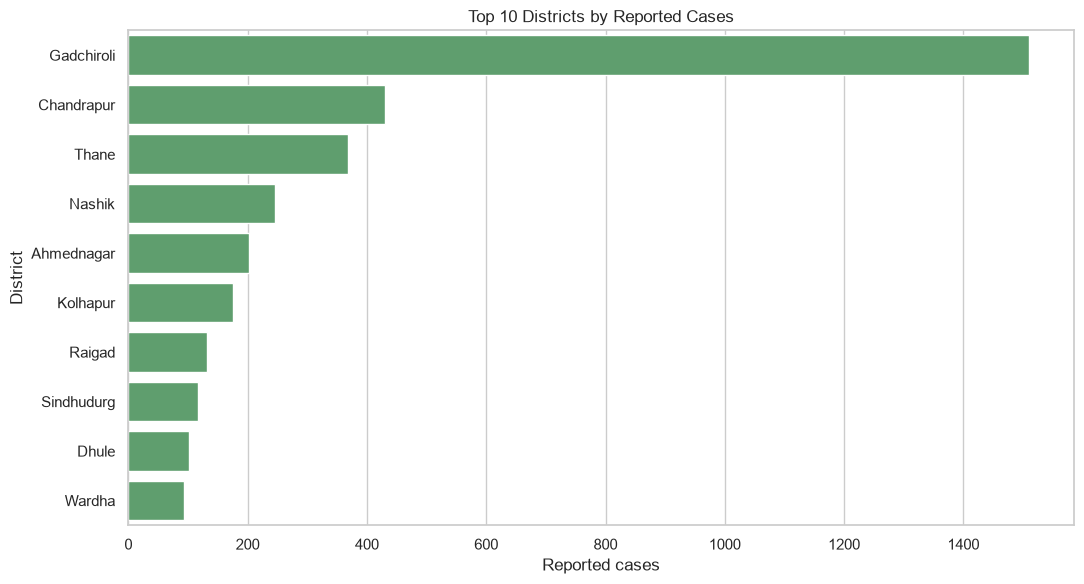

In [9]:
# Compare districts for the selected disease and year across all states.
district_data = df.copy()
if SELECT_DISEASE != "All":
    district_data = district_data[district_data["Disease"].str.casefold() == SELECT_DISEASE.casefold()]
if SELECT_YEAR != "All":
    district_data = district_data[district_data["Year"] == int(SELECT_YEAR)]

# If a state is selected, limit the district ranking to that state
if SELECT_STATE != "All":
    district_data = district_data[district_data["state_ut"].str.casefold() == SELECT_STATE.casefold()]

top_districts = (district_data.groupby("district")["Cases"].sum()
                 .sort_values(ascending=False).head(10).reset_index())

if not top_districts.empty:
    plt.figure(figsize=(11, 6))
    sns.barplot(data=top_districts, x="Cases", y="district", color="#55A868")
    plt.title("Top 10 Districts by Reported Cases")
    plt.xlabel("Reported cases")
    plt.ylabel("District")
    plt.tight_layout()
    plt.show()
else:
    print("No district data available for this selection.")

## 8. Graph 4 — Month-wise reported cases

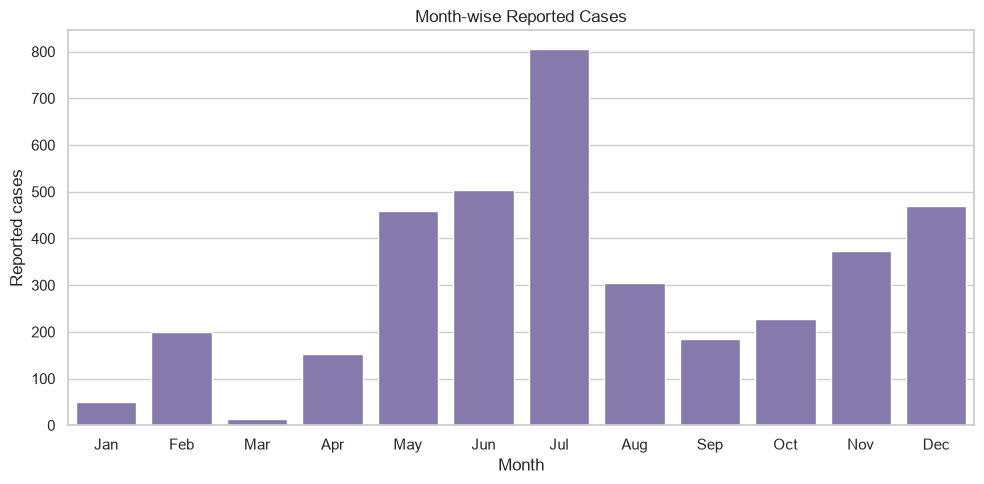

In [10]:
# Show the monthly pattern for the selected disease, geography and year.
month_data = filtered.dropna(subset=["Month"]).copy()

if not month_data.empty:
    monthly = month_data.groupby("Month", as_index=False)["Cases"].sum()
    month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                   "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
    monthly["Month_Name"] = monthly["Month"].astype(int).map(lambda x: month_names[x - 1])

    plt.figure(figsize=(10, 5))
    sns.barplot(data=monthly, x="Month_Name", y="Cases",
                order=month_names, color="#8172B3")
    plt.title("Month-wise Reported Cases")
    plt.xlabel("Month")
    plt.ylabel("Reported cases")
    plt.tight_layout()
    plt.show()
else:
    print("No monthly data available for this selection.")

## 9. Detailed tables for the selected area and disease

In [11]:
if not filtered.empty:
    # Disease-wise summary
    disease_summary = (filtered.groupby("Disease")
                       .agg(Reported_Cases=("Cases", "sum"),
                            Recorded_Deaths=("Deaths", "sum"),
                            Number_of_Reports=("Disease", "size"),
                            Districts_Reporting=("district", "nunique"))
                       .sort_values("Reported_Cases", ascending=False))
    display(disease_summary)

    # District-wise summary
    district_summary = (filtered.groupby(["state_ut", "district"])
                        .agg(Reported_Cases=("Cases", "sum"),
                             Recorded_Deaths=("Deaths", "sum"),
                             Number_of_Reports=("Disease", "size"),
                             First_Report=("Date", "min"),
                             Latest_Report=("Date", "max"))
                        .sort_values("Reported_Cases", ascending=False))
    display(district_summary)

    # Individual outbreak records
    display(filtered[["Date", "state_ut", "district", "Disease", "Cases", "Deaths",
                      "Latitude", "Longitude", "preci", "LAI", "Temp"]]
            .sort_values("Date", ascending=False))
else:
    print("No detailed records to display.")

,Reported_Cases,Recorded_Deaths,Number_of_Reports,Districts_Reporting
Disease,,,,
Malaria,3742.0,76.0,113,19


Reported_Cases  Recorded_Deaths  Number_of_Reports  \
state_ut    district                                                         
Maharashtra Gadchiroli          1510.0             41.0                 39   
            Chandrapur           431.0             13.0                 12   
            Thane                368.0              8.0                 14   
            Nashik               245.0              2.0                  6   
            Ahmednagar           203.0              0.0                  3   
            Kolhapur             176.0              1.0                  9   
            Raigad               132.0              0.0                  4   
            Sindhudurg           117.0              3.0                  7   
            Dhule                102.0              2.0                  4   
            Wardha                93.0              0.0                  2   
            Satara                74.0              1.0                  1   
            Ratnagiri             70.0              2.0                  2   
            Akola                 62.0              0.0                  2   
            Gondia                55.0              2.0                  2   
            Sangli                36.0              0.0                  2   
            Nandurbar             22.0              0.0                  1   
            Solapur               21.0              0.0                  1   
            Jalna                 14.0              1.0                  1   
            Jalgaon               11.0              0.0                  1   

                       First_Report Latest_Report  
state_ut    district                               
Maharashtra Gadchiroli   2011-11-22    2022-05-29  
            Chandrapur   2014-12-01    2022-06-04  
            Thane        2011-05-02    2021-05-02  
            Nashik       2009-09-12    2015-09-22  
            Ahmednagar   2011-05-20    2014-08-22  
            Kolhapur     2015-06-26    2019-08-29  
            Raigad       2012-07-31    2021-11-11  
            Sindhudurg   2017-01-02    2021-11-24  
            Dhule        2010-02-06    2014-10-30  
            Wardha       2013-07-04    2015-09-15  
            Satara       2014-12-09    2014-12-09  
            Ratnagiri    2009-12-09    2011-07-13  
            Akola        2011-07-27    2021-07-16  
            Gondia       2014-05-26    2022-06-13  
            Sangli       2014-07-16    2019-06-04  
            Nandurbar    2013-10-28    2013-10-28  
            Solapur      2010-09-30    2010-09-30  
            Jalna        2011-08-06    2011-08-06  
            Jalgaon      2011-07-22    2011-07-22

,Date,state_ut,district,Disease,Cases,Deaths,Latitude,Longitude,preci,LAI,Temp
183,2022-06-13,Maharashtra,Gondia,Malaria,47.0,1.0,21.455228,80.196273,0.028822,7.0,311.610000
158,2022-06-04,Maharashtra,Chandrapur,Malaria,3.0,1.0,20.096756,79.504548,0.006238,6.0,311.320000
134,2022-05-29,Maharashtra,Gadchiroli,Malaria,310.0,1.0,19.759070,80.162281,0.008762,10.0,311.086667
115,2022-05-25,Maharashtra,Chandrapur,Malaria,13.0,1.0,20.096756,79.504548,0.006072,NaN,314.545000
7,2022-02-09,Maharashtra,Gadchiroli,Malaria,1.0,1.0,19.759070,80.162281,0.000084,NaN,300.063333
...,...,...,...,...,...,...,...,...,...,...,...
8528,2010-09-30,Maharashtra,Solapur,Malaria,21.0,NaN,17.849907,75.276320,0.414223,NaN,303.926667
8260,2010-06-29,Maharashtra,Nashik,Malaria,24.0,NaN,20.011247,73.790236,0.390286,7.0,306.840000
7997,2010-02-06,Maharashtra,Dhule,Malaria,24.0,NaN,21.131702,74.489901,0.008374,4.0,305.480000
8964,2009-12-09,Maharashtra,Ratnagiri,Malaria,20.0,2.0,17.282608,73.456979,0.000069,14.0,301.868000


### 9.1 Heatmap: Monthly case concentration by district

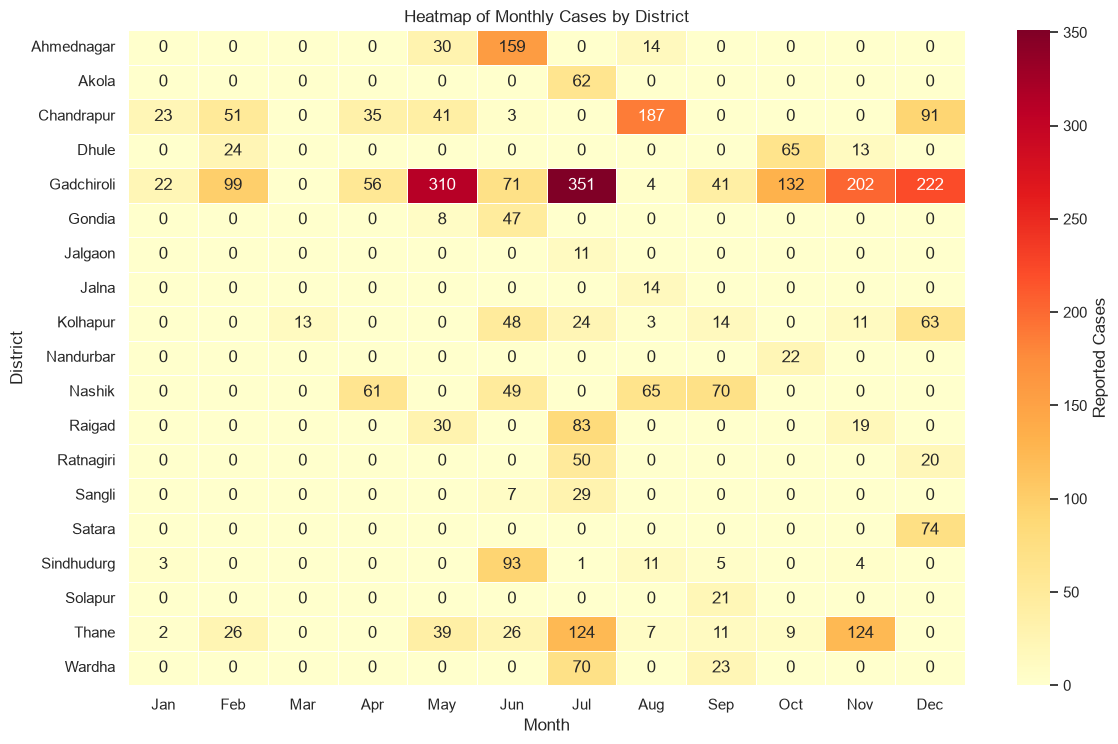

In [12]:
if not filtered.empty and filtered['district'].nunique() > 0:
    # Pivot the data to get District vs Month-Name with sum of cases
    heatmap_data = filtered.pivot_table(
        index='district',
        columns='Month',
        values='Cases',
        aggfunc='sum',
        fill_value=0
    )

    # Reorder columns to ensure all months 1-12 are represented
    all_months = list(range(1, 13))
    heatmap_data = heatmap_data.reindex(columns=all_months, fill_value=0)

    # Map numeric months to abbreviated names
    month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
    heatmap_data.columns = month_names

    # Limit to top districts for readability if there are too many
    if len(heatmap_data) > 20:
        top_dist_list = filtered.groupby('district')['Cases'].sum().nlargest(20).index
        heatmap_data = heatmap_data.loc[top_dist_list]
        title_suffix = " (Top 20 Districts by cases)"
    else:
        title_suffix = ""

    # Plotting
    plt.figure(figsize=(12, max(6, len(heatmap_data) * 0.4)))
    sns.heatmap(
        heatmap_data,
        cmap="YlOrRd",
        annot=True,
        fmt=",.0f",
        linewidths=.5,
        cbar_kws={'label': 'Reported Cases'}
    )
    plt.title(f"Heatmap of Monthly Cases by District{title_suffix}")
    plt.xlabel("Month")
    plt.ylabel("District")
    plt.tight_layout()
    plt.show()
else:
    print("No filtered data available to generate a heatmap.")

## 10. Statistical comparison of case counts

Use SciPy's non-parametric tests to compare reported case-count distributions across diseases or states. Set `COMPARISON_BY` to `"Disease"` or `"state_ut"`. The corresponding selector is intentionally not applied, while the other region/disease/year filters are respected. Two groups use a two-sided Mann-Whitney U test; three or more groups use Kruskal-Wallis. Groups with fewer than two reports are excluded from the test and identified in the summary.

These are exploratory comparisons of report-level counts, not population-adjusted disease risk. Reports may be clustered by place and time, so independence assumptions may not hold. A significant Kruskal-Wallis result indicates a difference somewhere among the groups; it does not identify which groups differ.

In [ ]:
from scipy import stats

# Compare diseases within the selected geography, or states for the selected disease.
COMPARISON_BY = "Disease"  # Choose "Disease" or "state_ut"
if COMPARISON_BY not in {"Disease", "state_ut"}:
    raise ValueError("COMPARISON_BY must be 'Disease' or 'state_ut'.")

comparison_data = df.dropna(subset=[COMPARISON_BY, "Cases"]).copy()

# Keep the other selections, but do not filter out the groups being compared.
if COMPARISON_BY != "state_ut" and SELECT_STATE != "All":
    comparison_data = comparison_data[
        comparison_data["state_ut"].str.casefold() == SELECT_STATE.casefold()
    ]
if SELECT_DISTRICT != "All":
    comparison_data = comparison_data[
        comparison_data["district"].str.casefold() == SELECT_DISTRICT.casefold()
    ]
if COMPARISON_BY != "Disease" and SELECT_DISEASE != "All":
    comparison_data = comparison_data[
        comparison_data["Disease"].str.casefold() == SELECT_DISEASE.casefold()
    ]
if SELECT_YEAR != "All":
    comparison_data = comparison_data[comparison_data["Year"] == int(SELECT_YEAR)]

if comparison_data.empty:
    print("No records available for the selected comparison and filters.")
else:
    grouped_cases = comparison_data.groupby(COMPARISON_BY, sort=True)["Cases"]
    comparison_summary = grouped_cases.agg(
        Number_of_Reports="count",
        Median_Cases="median",
        Q1_Cases=lambda values: values.quantile(0.25),
        Q3_Cases=lambda values: values.quantile(0.75),
    ).sort_values("Median_Cases", ascending=False)
    display(comparison_summary)

    test_groups = {
        str(name): values.dropna().to_numpy()
        for name, values in grouped_cases
        if values.count() >= 2
    }
    excluded_groups = comparison_summary.index[
        comparison_summary["Number_of_Reports"] < 2
    ].tolist()
    if excluded_groups:
        print("Excluded from testing (fewer than 2 reports):", excluded_groups)

    if len(test_groups) < 2:
        print("At least two groups with two or more reports are needed for a test.")
    else:
        alpha = 0.05
        print(f"Comparing {len(test_groups)} groups by {COMPARISON_BY} (alpha={alpha}).")
        tested_cases = pd.concat(
            [pd.Series(values) for values in test_groups.values()],
            ignore_index=True,
        )

        if tested_cases.nunique() == 1:
            test_result = None
            print("A comparison test is uninformative because all included case counts are identical.")
        elif len(test_groups) == 2:
            (group_a, values_a), (group_b, values_b) = test_groups.items()
            test_result = stats.mannwhitneyu(
                values_a, values_b, alternative="two-sided", method="auto"
            )
            test_name = "Mann-Whitney U"
            print(f"Groups: {group_a} (n={len(values_a)}) and {group_b} (n={len(values_b)})")
        else:
            values = list(test_groups.values())
            test_result = stats.kruskal(*values, nan_policy="omit")
            test_name = "Kruskal-Wallis H"

        if test_result is not None:
            p_value = test_result.pvalue
            print(f"{test_name} statistic: {test_result.statistic:.4f}")
            print(f"p-value: {p_value:.4g}")
            if p_value < alpha:
                print("Result: evidence of a difference in reported-case distributions.")
                if len(test_groups) > 2:
                    print("Kruskal-Wallis does not identify which specific groups differ.")
            else:
                print("Result: insufficient evidence of a difference at this significance level.")

,Number_of_Reports,Median_Cases,Q1_Cases,Q3_Cases
Disease,,,,
Suspected Dengue And Chikungunya,1,49.0,49.0,49.00
Cholera,58,45.5,21.0,77.75
Acute Diarrhoeal Disease,445,35.0,20.0,62.00
Dengue/Chikungunya,1,24.0,24.0,24.00
Acute Gastroenteritis,26,23.0,17.0,30.75
Dengue Chikungunya,1,19.0,19.0,19.00
Dengue,370,18.0,10.0,31.00
Malaria,113,18.0,9.0,41.00
Chikungunya,147,17.0,9.5,30.50


Excluded from testing (fewer than 2 reports): ['Suspected Dengue And Chikungunya', 'Dengue/Chikungunya', 'Dengue Chikungunya', 'Dengue Fever', 'Malaria (PV)']
Comparing 9 groups by Disease (alpha=0.05).
Kruskal-Wallis H statistic: 182.7698
p-value: 2.697e-35
Result: evidence of a difference in reported-case distributions.
Kruskal-Wallis does not identify which specific groups differ.


## 11. Important notes

- Cases are reported counts, not population-adjusted rates.
- Missing death values are not the same as zero deaths.
- Disease labels are kept exactly as supplied; similar labels are not automatically combined.
- Graphs show patterns in this dataset and do not prove the cause of an outbreak.